# 第15章 工具封装

## 本章导读

候选 kernel 能编译，但它算对了吗？一次时间更短，就值得保留吗？我们从可编辑的向量加法开始，故意写错一次，修复后观察时间样本，再完成接受判定。

本页图表来自当前运行，不预设哪一个 block 更快。默认流程使用真实 GPU 工具，无需模型密钥。前置：[第14章](../chapter14/chapter14.ipynb)，对照阅读：[本章正文](../../../docs/part3-agent/chapter15/index.md)。


In [ ]:
%run ../../common/bootstrap.py

import json
import pandas as pd
from IPython.display import display
import hello_gpu as gpu
from hello_gpu import agentlab
cfg = gpu.settings()
env = gpu.environment()
env


## 15.1 先固定任务，再设计工具

继续计算 `output = x + y`。FP16 每个元素占 2 Byte：读取两个输入、写一个输出，逻辑数据量为 $6N$ Byte。这个模型帮助解释工作量，实际时间要通过运行得到。


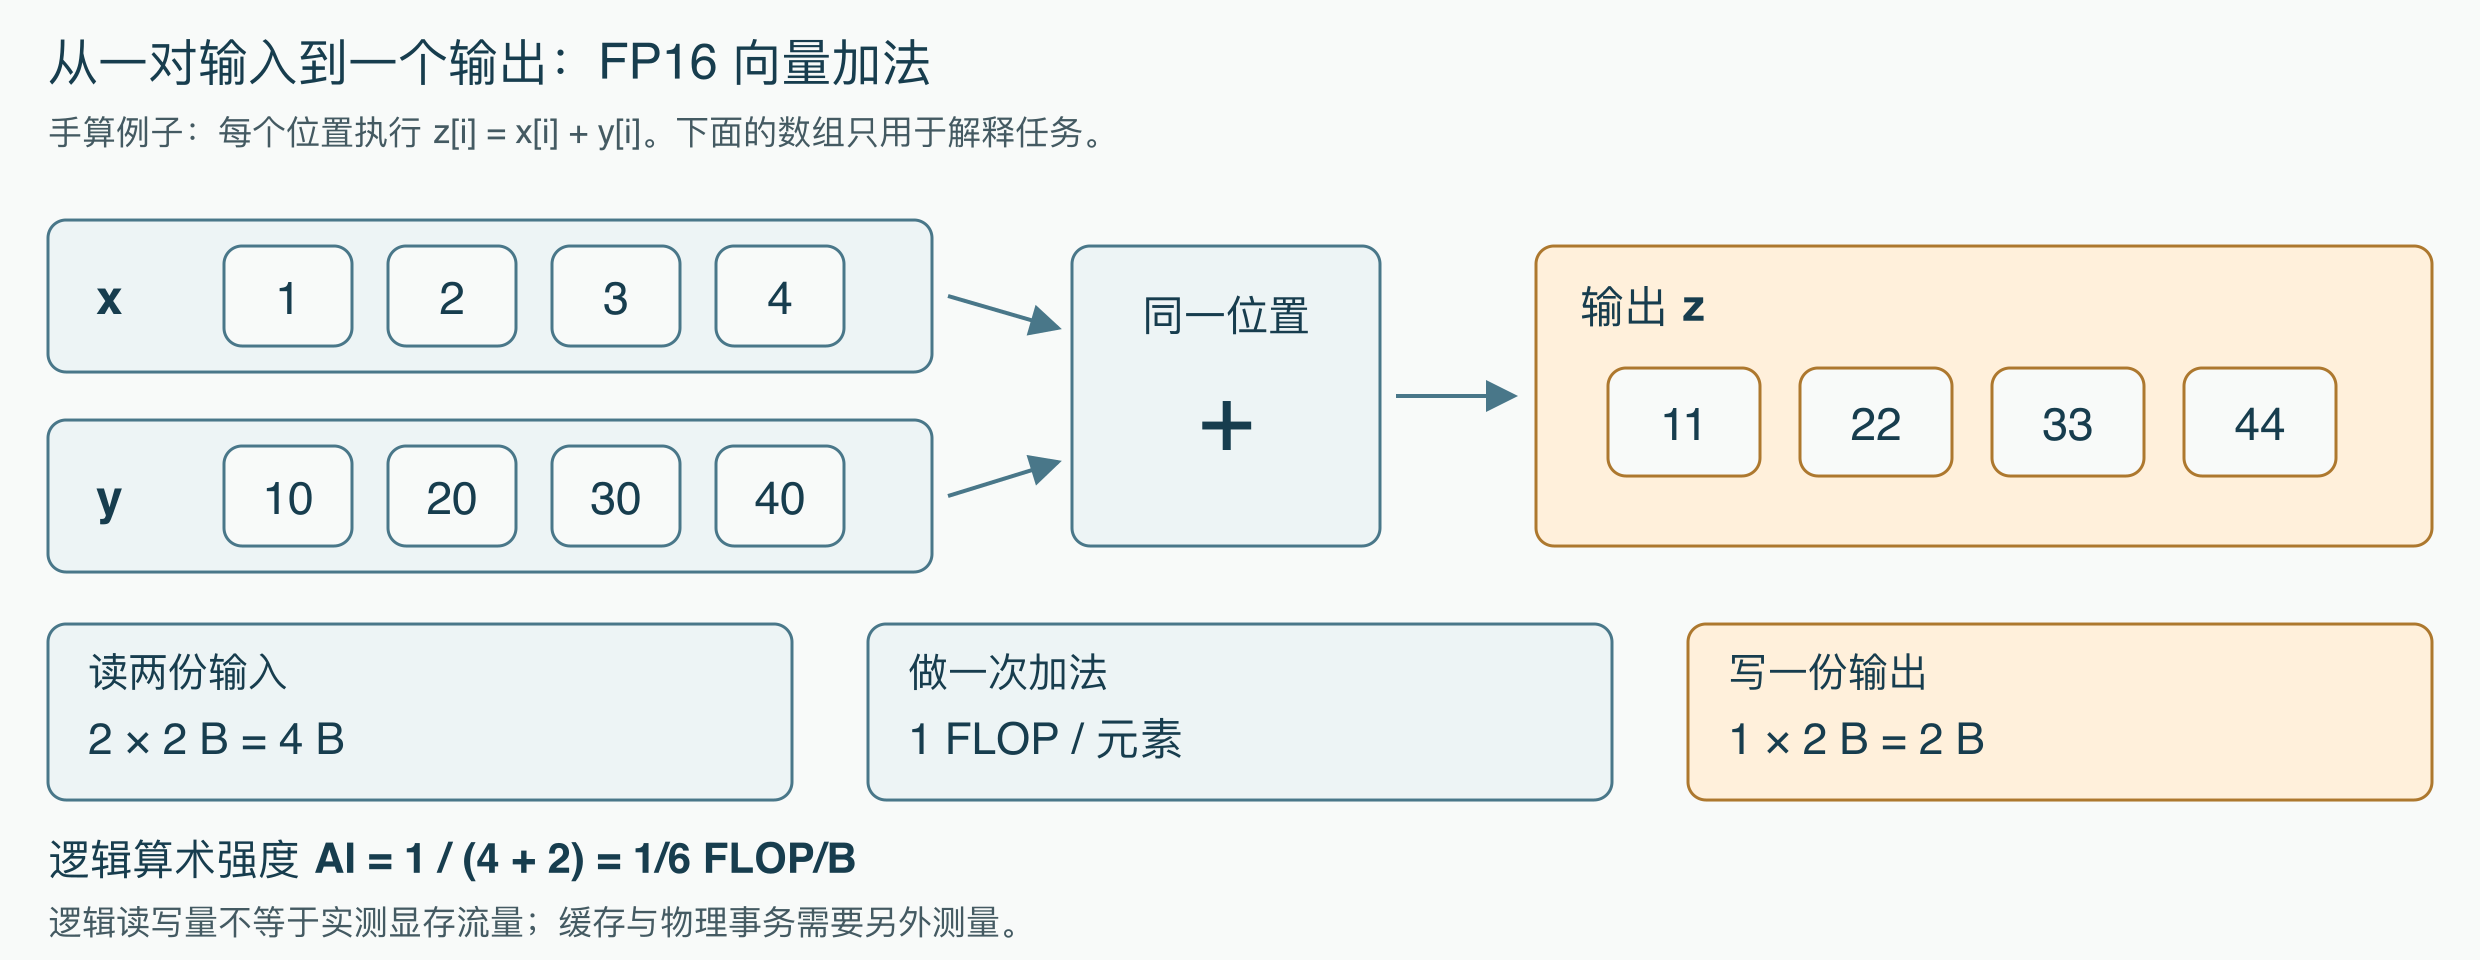

*每个位置读两个输入、做一次加法、写一个输出；逻辑读写量不等于实测流量。*


下面是完整候选源码。`launch` 接收评测器准备的输入、输出和元素数；`BLOCK` 表示一个 program 的逻辑片段长度。输出提前分配，尾部使用 `mask` 保护。先读懂 `result = a + b` 和 `valid`，随后亲手修改它。


In [ ]:
SOURCE = """import triton
import triton.language as tl

@triton.jit
def add_kernel(x, y, output, n_elements, BLOCK: tl.constexpr):
    offsets = tl.program_id(0) * BLOCK + tl.arange(0, BLOCK)
    valid = offsets < n_elements
    a = tl.load(x + offsets, mask=valid, other=0)
    b = tl.load(y + offsets, mask=valid, other=0)
    result = a + b
    tl.store(output + offsets, result, mask=valid)

def launch(x, y, output, n_elements):
    block_size = 256
    grid = (triton.cdiv(n_elements, block_size),)
    add_kernel[grid](x, y, output, n_elements, BLOCK=block_size,
                     num_warps=4)
"""
SOURCE = SOURCE.replace("block_size = 256", f"block_size = {cfg['block']}")


In [ ]:
lab = agentlab.Lab("chapter15", cfg, baseline_source=SOURCE)
display(pd.Series(lab.task_summary()))


## 15.2 编译通过之后，还要对答案

先把加法改成减法。它仍是合法计算，因此“编译成功”不足以说明正确。工具会用固定的非均匀输入核对整个输出，并把失败阶段返回给我们。


In [ ]:
wrong_source = SOURCE.replace("result = a + b", "result = a - b")
agentlab.source_diff(SOURCE, wrong_source)
wrong_check = lab.call("compile_kernel", source=wrong_source)
agentlab.show(wrong_check, title="把加法改成减法之后")
assert not wrong_check["ok"], "数值错误应被正确性检查拒绝"


**观察**：查看卡片中的失败阶段和原因。此次失败说明答案错误，不代表 kernel 太慢；没有通过检查的候选不应获得有效性能结论。


In [ ]:
fixed_source = wrong_source.replace("result = a - b", "result = a + b")
fixed_check = lab.call("compile_kernel", source=fixed_source)
agentlab.show(fixed_check, title="修复后重新检查")
assert fixed_check["ok"], "检查失败时先阅读卡片中的原因"


## 15.3 计时工具回答“这份源码有多快”

正确实现进入预热和正式采样。先看单个样本，再看中心位置；一次最快值不能代表稳定改善。这里的样本描述评测器的批平均时间，计时方式保持固定。


In [ ]:
baseline_measurement = lab.preflight()
agentlab.show(baseline_measurement, title="固定基线的实际测量")
assert baseline_measurement["ok"], "基线必须先正确运行"
_ = lab.sample_plot(baseline_measurement)


**观察**：样本是否集中？是否有较慢的样本？记下本机观察，再继续比较。曲线与统计值的单位、设备和任务条件来自本次评测记录。


## 15.4 用 Roofline 建立假设

算法强度为加法次数除以逻辑字节数：FP16 向量加法为 $N/(6N)=1/6$ FLOP/Byte。低算法强度提示我们研究访存与工作分配，但缓存、输入规模和提交开销也会影响实际结果。

先计算任务模型；如果没有校准带宽和硬件流量证据，就不画一个假定的 Roofline 上限，也不把逻辑有效带宽当作物理显存带宽。


In [ ]:
cost = lab.task["costModel"]
display(pd.Series({
    "加法次数 FLOP": cost["flops"],
    "逻辑读写量 Byte": cost["bytes"],
    "算法强度 FLOP/Byte": cost["flops"] / cost["bytes"],
    "本轮假设": "只扩大 block，观察工作分配是否改善实际时间",
    "仍需证据": "硬件流量、资源使用和设备带宽校准",
}))


## 15.5 接受候选需要重新配对比较

只把 `block_size` 扩大两倍，输入和数学语义保持固定。先看源码差异，再让接受工具重新检查候选，并与当前实现配对计时。这个决定不直接使用前面一次测量的最快值。


In [ ]:
next_source = SOURCE.replace(f"block_size = {cfg['block']}",
                             f"block_size = {cfg['block'] * 2}")
agentlab.source_diff(SOURCE, next_source)
before = lab.best_path.read_text()
decision = lab.call("accept_candidate", source=next_source,
                    change="只把 block_size 扩大两倍")
agentlab.show(decision, title="候选是否值得保留")
_ = lab.pair_plot(decision)
if not decision.get("accepted", False):
    assert lab.best_path.read_text() == before


**观察**：接受或拒绝都可能发生。先核对接受理由与配对样本，再解释当前实现是否变化。源码改动更大或 block 更大都不是接受条件。


## 15.6 根据失败阶段决定下一步

再次提交减法版本，观察它不会替换当前实现。正确性失败要修复数学语义；编译失败要检查语法或配置；正确但没有稳定改善时，可以保持当前版本并调整下一项假设。


In [ ]:
before = lab.best_path.read_text()
rejected = lab.call("accept_candidate", source=wrong_source,
                    change="反例：把加法写成减法")
agentlab.show(rejected, title="错误候选的接受判定")
assert not rejected.get("accepted", False)
assert lab.best_path.read_text() == before
display(lab.table())


## 15.7 练习：为结果找对解释

输入长度不是 block 的整数倍时，最后一个 program 只有一部分位置有效。先用小表检查 `offsets < n` 的含义，再对长度 4097 的真实 GPU 输入检查。


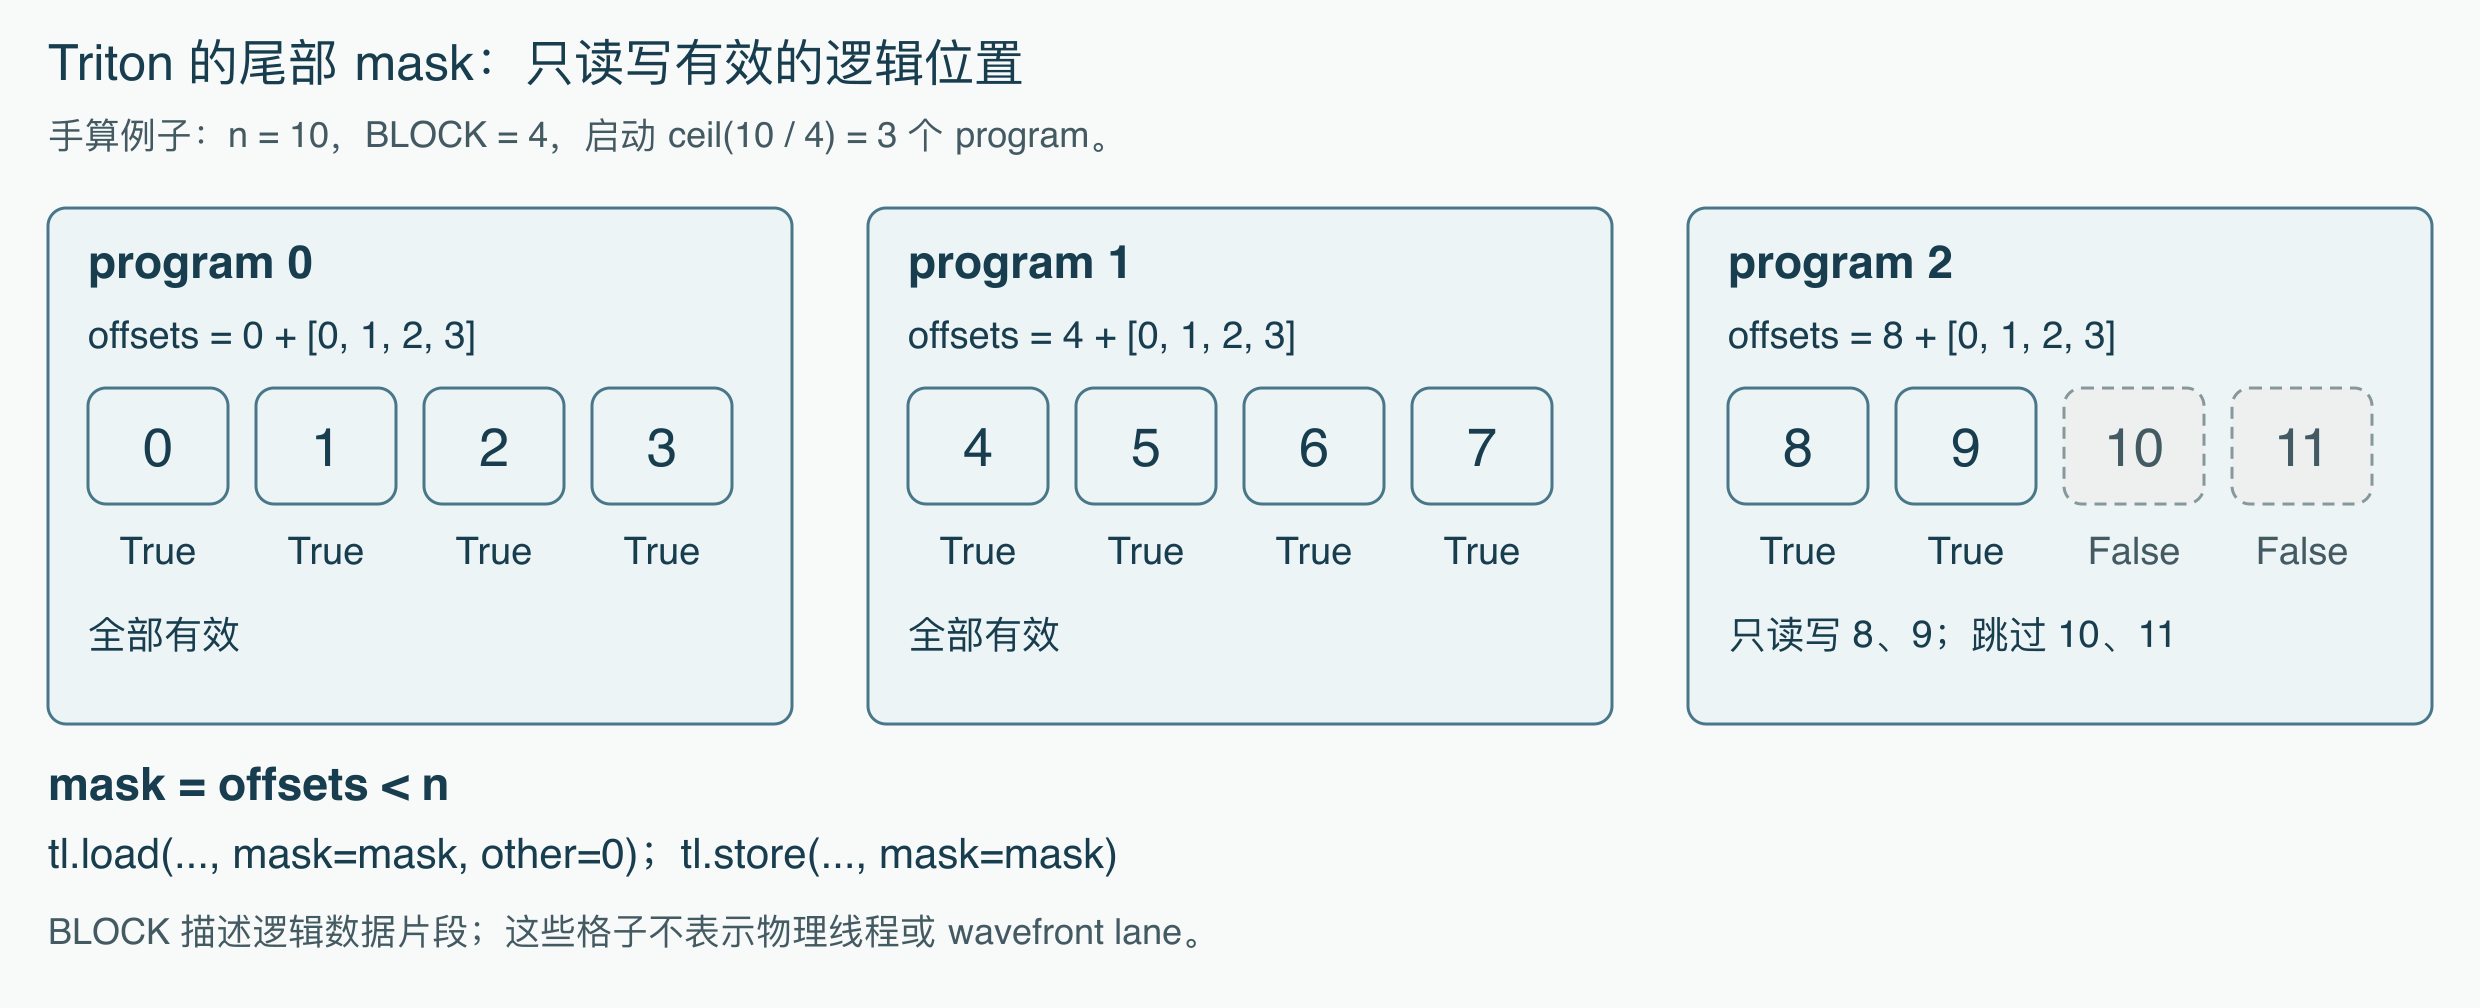

*n=10、BLOCK=4 的逻辑片段；最后一个 program 通过 mask 跳过 10、11。*


In [ ]:
n_small, block_small = 10, 4
offsets = list(range(12))
valid = [i < n_small for i in offsets]  # 练习：解释这个条件保护了什么
display(pd.DataFrame({"program": [i // block_small for i in offsets],
                      "offset": offsets, "允许读写": valid}))
assert [i for i, enabled in zip(offsets, valid) if enabled] == list(range(n_small))


In [ ]:
tail_lab = agentlab.Lab("chapter15-tail", cfg | {"n": 4097},
                        baseline_source=SOURCE)
tail_check = tail_lab.call("compile_kernel", source=SOURCE)
agentlab.show(tail_check, title="长度 4097 的尾部检查")
assert tail_check["ok"]


**练习**：只修改一个合法的 block 配置，重复检查、计时和接受判定。写出“改了什么—实际结果—是否保留—还不能解释什么”。再改变输入规模复测，比较结果是否仍然成立；不要把一份任务的结论直接推广到其他规模。


## 本章小结

你已读到实际 kernel，制造并修复数值错误，观察原始时间样本，并用配对比较完成接受判定。应能解释失败发生在哪一步、当前实现为什么变化或保持不变。下一章把这些工具连成可以跟踪状态的循环。


## 延伸阅读

- [本章正文](../../../docs/part3-agent/chapter15/index.md)
- [Triton 向量加法教程](https://triton-lang.org/main/getting-started/tutorials/01-vector-add.html)
- [第16章 notebook](../chapter16/chapter16.ipynb)
